# Carregamento e Preparação dos Dados (série histórica IFES)

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Leitura do arquivo CSV
df = pd.read_csv('dados_investimento_e_vagas_ifes.csv', sep=',')
# Calculando amplitude dos valores de investimento e vagas do IFES
amplitude = df.max() - df.min()
print(amplitude)


ano                                                     30.0
investimento_total_ifes_bilhoes_brl                     46.7
investimento_assistencia_estudantil_bilhoes_brl          1.3
num_vagas_estudantes                               1042900.0
num_vagas_docente                                    71300.0
num_vagas_tae                                        35900.0
num_terceirizados                                    50900.0
dtype: float64


# Evolução Temporal e Ajuste de Escalas

### Interpretação dos dados
Entre 1996 e 2026, o investimento total registrado passa de R$ 32,1 bilhões para R$ 61,8 bilhões, registrando a máxima de R$ 76,5 bilhões em 2014. No mesmo intervalo, as vagas de estudantes aumentam de 342,1 mil para 1,385 milhão; a série de vagas tem uma queda pontual em 2021 e volta a crescer depois. As duas séries crescem no longo prazo, mas não no mesmo ritmo: essa coincidência temporal, por si só, não demonstra que o investimento causou o aumento das vagas nem permite concluir impactos sobre os estudantes.

### Justificativa do design
Gráficos de linhas são adequados para acompanhar tendências anuais e localizar mudanças ao longo do tempo. Os dois painéis compartilham o eixo dos anos, mas têm eixos Y separados porque mostram grandezas e unidades diferentes (bilhões de reais e vagas), assim não se usa uma escala comum enganosa. Os marcadores e grades de ano e indicadores das informações facilitam a leitura.

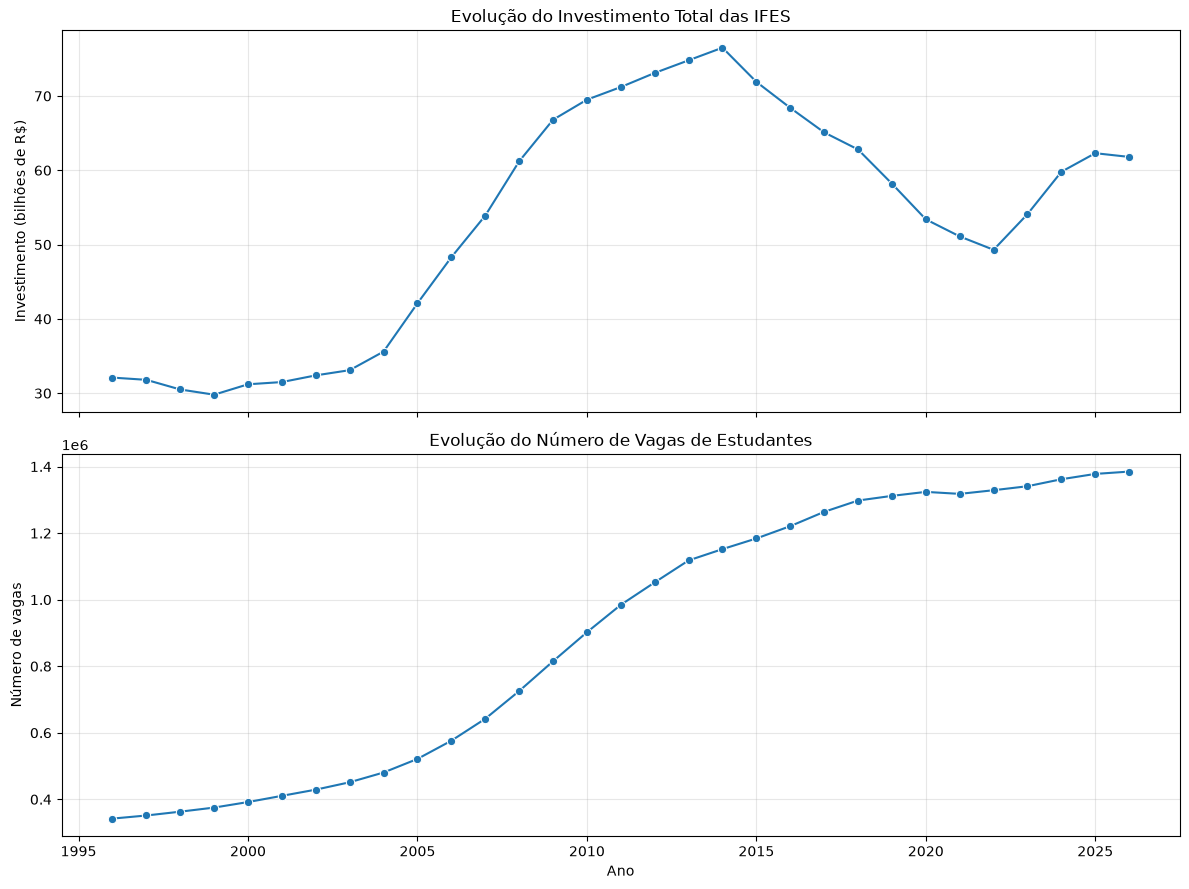

In [ ]:
# Análise da evolução anual do investimento total e das vagas de estudantes

indicadores_por_ano = (
    df.groupby('ano', as_index=False)
      .agg({
          'investimento_total_ifes_bilhoes_brl': 'sum',
          'num_vagas_estudantes': 'sum'
      })
      .sort_values('ano')
)


fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

sns.lineplot(
    data=indicadores_por_ano,
    x='ano',
    y='investimento_total_ifes_bilhoes_brl',
    marker='o',
    ax=axes[0]
)
axes[0].set_title('Evolução do Investimento Total nos IFES')
axes[0].set_ylabel('Investimento (bilhões de R$)')
axes[0].set_xlabel('')
axes[0].grid(True, alpha=0.3)

sns.lineplot(
    data=indicadores_por_ano,
    x='ano',
    y='num_vagas_estudantes',
    marker='o',
    ax=axes[1]
)
axes[1].set_title('Evolução do Número de Vagas de Estudantes')
axes[1].set_xlabel('Ano')
axes[1].set_ylabel('Número de vagas')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#  Análise de Proporção de Força de Trabalho (Docentes vs. TAEs)

### Interpretação dos dados
A proporção calculada é de vagas de estudantes para cada vaga de docente ou de TAE, não de estudantes matriculados por profissional efetivamente em exercício. Em 1996, havia cerca de 12,76 vagas de estudantes por vaga de docente e 7,94 por vaga de TAE. As séries se aproximam em 2010 (13,42 e 13,50) e depois a proporção por TAE fica acima da proporção por docente. Em 2026, os valores são aproximadamente 14,12 e 19,16. A proporção por docente permanece relativamente estável nos anos mais recentes, enquanto a proporção por TAE continua maior.

### Justificativa do design
As linhas mostram a trajetória anual e tornam visível o ponto em que as proporções se cruzam. As duas séries usam o mesmo eixo Y porque ambas têm a mesma unidade de vagas de estudantes por vaga profissional, o que permite compará-las diretamente no mesmo plot. Cores e marcadores diferentes distinguem docente de TAE e a legenda identifica cada linha, e os rótulos dos eixos, a grade e a rotação dos anos apoiam a leitura.

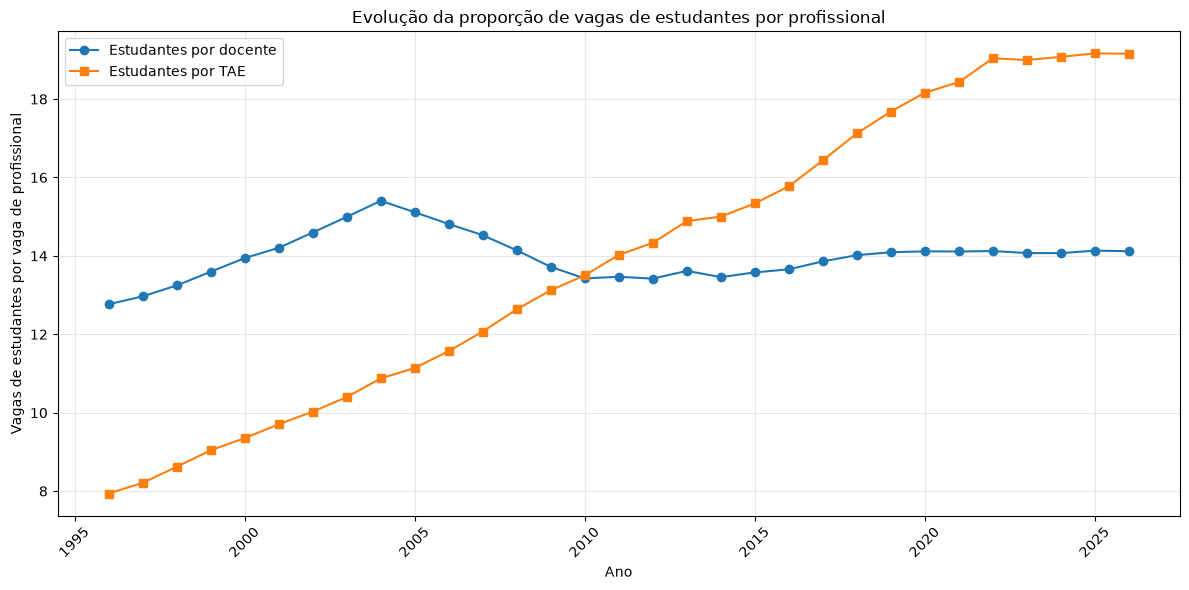

In [19]:
# Proporções de vagas por docente e TAE por ano
proporcoes_por_ano = (
    df.groupby('ano', as_index=False)
      .agg({
          'num_vagas_estudantes': 'sum',
          'num_vagas_docente': 'sum',
          'num_vagas_tae': 'sum'
      })
      .sort_values('ano')
)

proporcoes_por_ano['Estudantes por docente'] = (
    proporcoes_por_ano['num_vagas_estudantes']
    / proporcoes_por_ano['num_vagas_docente']
)
proporcoes_por_ano['Estudantes por TAE'] = (
    proporcoes_por_ano['num_vagas_estudantes']
    / proporcoes_por_ano['num_vagas_tae']
)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(proporcoes_por_ano['ano'], proporcoes_por_ano['Estudantes por docente'], marker='o', label='Estudantes por docente', color='tab:blue')
ax.plot(proporcoes_por_ano['ano'], proporcoes_por_ano['Estudantes por TAE'], marker='s', label='Estudantes por TAE', color='tab:orange')
ax.set_title('Evolução da proporção de vagas de estudantes por profissional')
ax.set_xlabel('Ano')
ax.set_ylabel('Vagas de estudantes por vaga de profissional')
ax.tick_params(axis='x', rotation=45)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Correlação entre Fatores e Desempenho Orçamentário

### Interpretação dos dados
Cada ponto resume um período de quatro anos: o eixo X mostra a média anual de vagas de estudantes e o eixo Y, a média anual do investimento em assistência estudantil. A média de investimento sobe de aproximadamente R$ 0,023 bilhão no período inicial para R$ 1,26 bilhão em 2015-2018, entre 2019-2022 cai para R$ 1,10 bilhão, enquanto a média de vagas continua aumentando. Em 2023-2026, ambas as médias voltam a crescer (R$ 1,19 bilhão e cerca de 1,367 milhão de vagas).

O primeiro intervalo é 1995-1998, mas há dados apenas para 1996-1998, por isso, sua média cobre três anos, enquanto as demais cobrem quatro. Os intervalos são uma forma de agrupamento temporal e não devem ser interpretados automaticamente como períodos de uma única administração: por exemplo, 2015-2018 atravessa a mudança de presidente de 2016.

### Justificativa do design
O scatter plot é apropriado para comparar simultaneamente duas medidas numéricas agregadas: o tamanho da bolha acrescenta uma terceira informação (investimento médio por vaga); A cor azul única evita sugerir uma categoria que não está sendo mencionada, e os rótulos identificam os períodos sem exigir uma legenda para pontos individuais; O texto dentro do gráfico explica a variável pelo tamanho e a tabela de médias, medianas e somas exibida antes do gráfico permite consultar os valores exatos.

,Período,Investimento assistência - média (bi R$),Investimento assistência - mediana (bi R$),Investimento assistência - soma (bi R$),Vagas de estudantes - média,Vagas de estudantes - mediana,Vagas de estudantes - soma
0,1995-1998 (dados 1996-1998),0.023333,0.020,0.07,3.521333e+05,351400.0,1056400
1,1999-2002,0.040000,0.040,0.16,4.016500e+05,401150.0,1606600
2,2003-2006,0.110000,0.100,0.44,5.073750e+05,501000.0,2029500
3,2007-2010,0.515000,0.515,2.06,7.711250e+05,770150.0,3084500
4,2011-2014,1.142500,1.165,4.57,1.076625e+06,1085000.0,4306500
5,2015-2018,1.260000,1.265,5.04,1.241750e+06,1242500.0,4967000
6,2019-2022,1.100000,1.120,4.40,1.320750e+06,1321000.0,5283000
7,2023-2026,1.190000,1.215,4.76,1.366500e+06,1370000.0,5466000


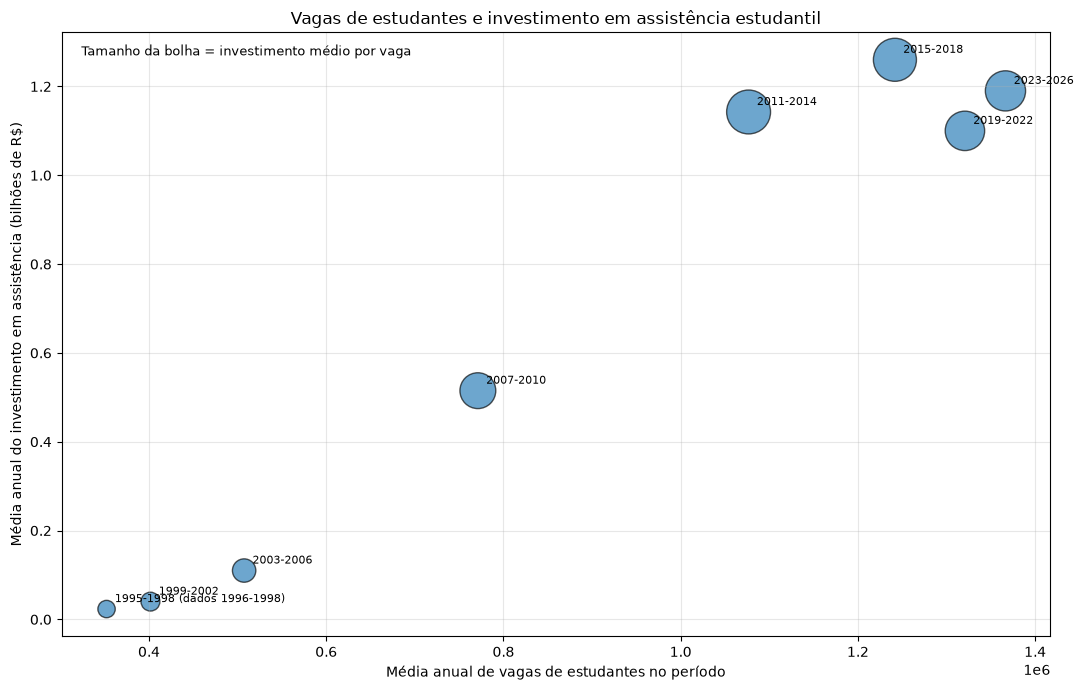

In [24]:
# Estatísticas descritivas feitas em períodos consecutivos de quatro anos (mandatos presidenciais)
ano_inicio_mandato = 1995

dados_por_periodo = df.assign(
    periodo_inicio=ano_inicio_mandato
    + ((df['ano'] - ano_inicio_mandato) // 4) * 4
)

resumo_periodos = (
    dados_por_periodo.groupby('periodo_inicio', as_index=False)
    .agg(
        ano_inicial_dados=('ano', 'min'),
        ano_final=('ano', 'max'),
        anos_com_dados=('ano', 'count'),
        investimento_medio=('investimento_assistencia_estudantil_bilhoes_brl', 'mean'),
        investimento_mediano=('investimento_assistencia_estudantil_bilhoes_brl', 'median'),
        investimento_total=('investimento_assistencia_estudantil_bilhoes_brl', 'sum'),
        vagas_media=('num_vagas_estudantes', 'mean'),
        vagas_mediana=('num_vagas_estudantes', 'median'),
        vagas_total=('num_vagas_estudantes', 'sum')
    )
    .sort_values('periodo_inicio')
)
resumo_periodos['periodo'] = resumo_periodos.apply(
    lambda linha: (
        f"{int(linha['periodo_inicio'])}-{int(linha['periodo_inicio']) + 3}"
        + (
            f" (dados {int(linha['ano_inicial_dados'])}-{int(linha['ano_final'])})"
            if linha['anos_com_dados'] < 4
            else ""
        )
    ),
    axis=1
)

display(
    resumo_periodos[[
        'periodo',
        'investimento_medio', 'investimento_mediano', 'investimento_total',
        'vagas_media', 'vagas_mediana', 'vagas_total'
    ]].rename(columns={
        'periodo': 'Período',
        'investimento_medio': 'Investimento assistência - média (bi R$)',
        'investimento_mediano': 'Investimento assistência - mediana (bi R$)',
        'investimento_total': 'Investimento assistência - soma (bi R$)',
        'vagas_media': 'Vagas de estudantes - média',
        'vagas_mediana': 'Vagas de estudantes - mediana',
        'vagas_total': 'Vagas de estudantes - soma'
    })
)

resumo_periodos['investimento_por_vaga'] = (
    resumo_periodos['investimento_medio'] / resumo_periodos['vagas_media']
)
tamanhos_bolhas = 100 + 900 * (
    resumo_periodos['investimento_por_vaga']
    / resumo_periodos['investimento_por_vaga'].max()
)

fig, ax = plt.subplots(figsize=(11, 7))
bolhas = ax.scatter(
    resumo_periodos['vagas_media'],
    resumo_periodos['investimento_medio'],
    s=tamanhos_bolhas,
    alpha=0.65,
    color='tab:blue',
    edgecolors='black'
)

for _, linha in resumo_periodos.iterrows():
    ax.annotate(
        linha['periodo'],
        (linha['vagas_media'], linha['investimento_medio']),
        xytext=(6, 5),
        textcoords='offset points',
        fontsize=8
    )

ax.set_title('Vagas de estudantes e investimento em assistência estudantil')
ax.set_xlabel('Média anual de vagas de estudantes no período')
ax.set_ylabel('Média anual do investimento em assistência (bilhões de R$)')
ax.grid(True, alpha=0.3)
ax.text(
    0.02, 0.98,
    'Tamanho da bolha = investimento médio por vaga',
    transform=ax.transAxes,
    va='top',
    fontsize=9
)
fig.tight_layout()
plt.show()

# Filtragem Condicional de Anos Críticos

### Interpretação dos dados
O destaque identifica 11 anos em que o investimento nominal em assistência estudantil ficou igual ou abaixo do ano anterior: 1997, 1999, 2001, 2015, 2017-2022 e 2026. A série de vagas aparece no painel inferior para permitir a comparação temporal, por exemplo, a queda de investimento entre 2017 e 2022 ocorre enquanto as vagas variam pouco e tem uma redução pontual em 2021.

### Justificativa do design
As linhas mantêm o contexto de toda a série anual, enquanto marcadores vermelhos e faixas translúcidas chamam atenção para os anos classificados sem ocultar a tendência. A legenda explica ambos os destaques. Os painéis compartilham o eixo do tempo, mas preservam escalas Y próprias para investimento e vagas, que têm unidades diferentes. O critério é explícito e reproduzível: variação anual menor ou igual a zero. 1996 não é classificado porque não há ano anterior para comparação.

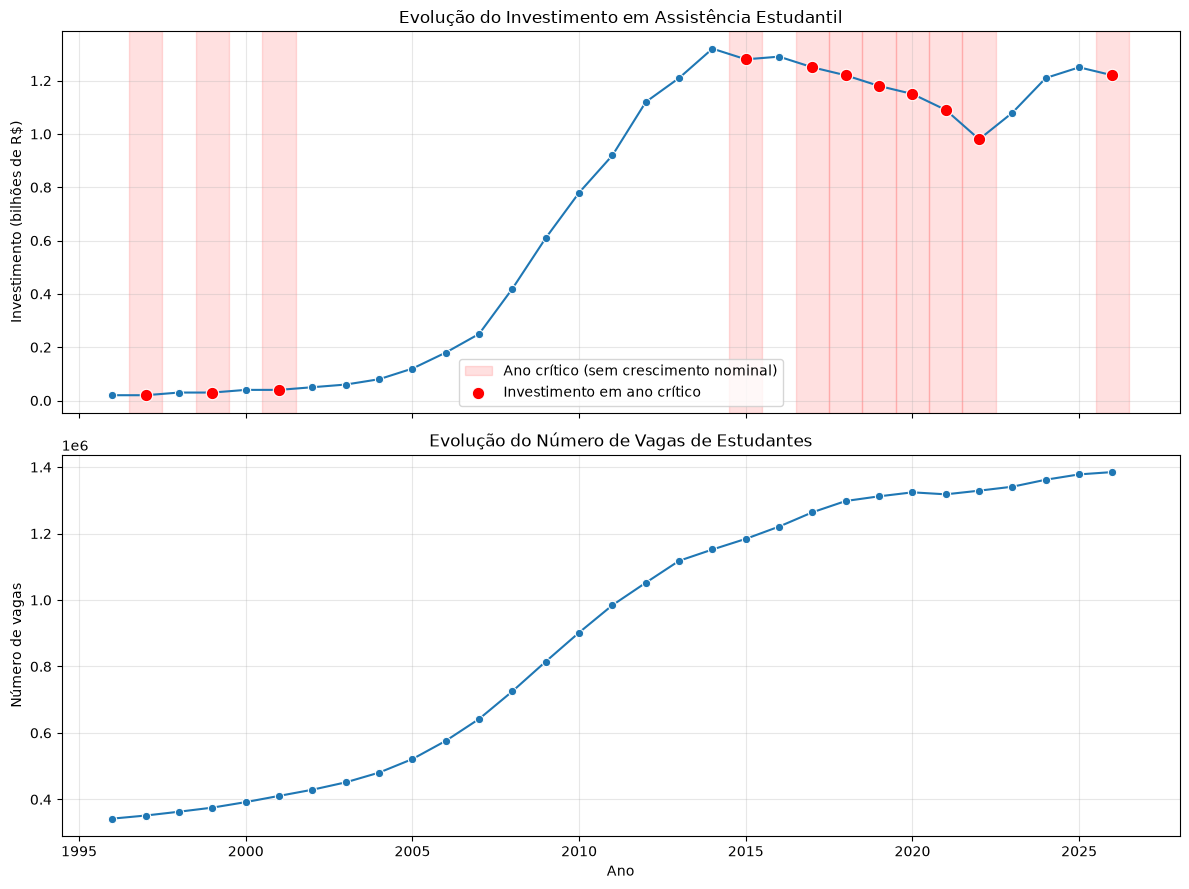

In [23]:
# Análise de anos críticos da assistência estudantil (anos de menor investimento, cortes e estagnação)

indicadores_por_ano = (
    df.groupby('ano', as_index=False)
      .agg({
          'investimento_assistencia_estudantil_bilhoes_brl': 'sum',
          'num_vagas_estudantes': 'sum'
      })
      .sort_values('ano')
)

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

sns.lineplot(
    data=indicadores_por_ano,
    x='ano',
    y='investimento_assistencia_estudantil_bilhoes_brl',
    marker='o',
    ax=axes[0]
)

# Considera crítico o ano em que o investimento nominal não cresceu em relação ao anterior.
anos_criticos = indicadores_por_ano[
    indicadores_por_ano['investimento_assistencia_estudantil_bilhoes_brl'].diff() <= 0
]
for indice, ano in enumerate(anos_criticos['ano']):
    axes[0].axvspan(
        ano - 0.5,
        ano + 0.5,
        color='red',
        alpha=0.12,
        label='Ano crítico (sem crescimento nominal)' if indice == 0 else '_nolegend_'
    )
axes[0].scatter(
    anos_criticos['ano'],
    anos_criticos['investimento_assistencia_estudantil_bilhoes_brl'],
    color='red',
    edgecolor='white',
    linewidth=0.8,
    s=80,
    zorder=3,
    label='Investimento em ano crítico'
)
axes[0].legend()
axes[0].set_title('Evolução do Investimento em Assistência Estudantil')
axes[0].set_ylabel('Investimento (bilhões de R$)')
axes[0].set_xlabel('')
axes[0].grid(True, alpha=0.3)

sns.lineplot(
    data=indicadores_por_ano,
    x='ano',
    y='num_vagas_estudantes',
    marker='o',
    ax=axes[1]
)
axes[1].set_title('Evolução do Número de Vagas de Estudantes')
axes[1].set_xlabel('Ano')
axes[1].set_ylabel('Número de vagas')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Métricas Customizadas via apply e Paletas de Cores

### Interpretação dos dados
A classificação compara, em cada ano, as variações percentuais do investimento em assistência estudantil e do número de vagas em relação ao ano anterior. Na série atual, 19 anos são classificados como Alta Expansão, 3 como Média Expansão, 8 como Retração Orçamentária e 1996 fica como Sem comparação. A categoria de retração indica queda no investimento em assistência estudantil, não é uma avaliação do orçamento total dos IFES nem uma medida abrangente de consolidação institucional, mas reflete cortes nos fundos do governo que são enviados para esses Institutos.

A regra implementada classifica como Alta Expansão os anos em que investimento e vagas crescem; como Retração Orçamentária, aqueles em que o investimento cai; e como Média Expansão os demais casos, incluindo investimento crescente com vagas estáveis ou em queda, ou investimento sem crescimento.

### Justificativa do design
A série cinza mostra o nível anual do investimento em assistência estudantil, e as cores dos marcadores destacam as classes produzidas pela função. Verde comunica crescimento conjunto, amarelo uma situação intermediária, vermelho a queda do investimento e cinza a ausência de comparação. A legenda identifica as categorias; a tabela apresenta as variações percentuais de investimento e vagas usadas para interpretá-las. Foram escolhidos tons de cores das famílias sequenciais `Greens`, `YlOrBr` e `Reds`, mas cada classe usa um tom fixo.

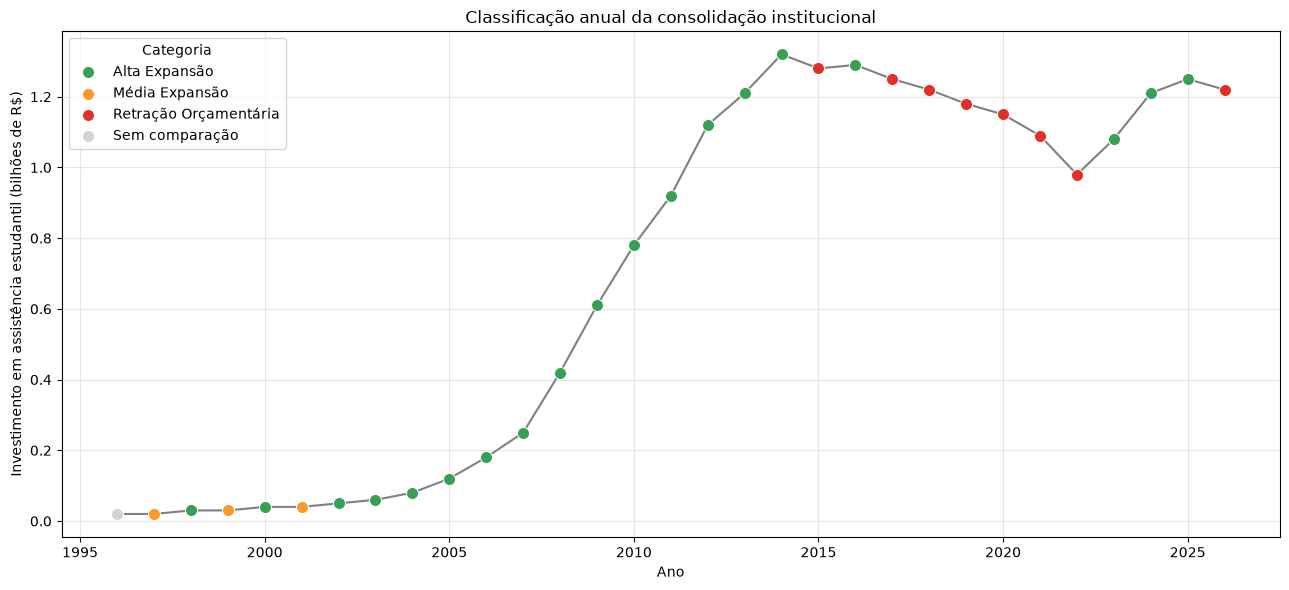

,Ano,Variação do investimento (%),Variação das vagas (%),Categoria de consolidação
0,1996,NaN,NaN,Sem comparação
1,1997,0.00,2.72,Média Expansão
2,1998,50.00,3.27,Alta Expansão
3,1999,0.00,3.39,Média Expansão
4,2000,33.33,4.42,Alta Expansão
5,2001,0.00,4.77,Média Expansão
6,2002,25.00,4.53,Alta Expansão
7,2003,20.00,5.17,Alta Expansão
8,2004,33.33,6.49,Alta Expansão
9,2005,50.00,8.49,Alta Expansão


In [25]:
# Classifica os anos conforme a variação do investimento e das vagas de estudantes.
def classificar_consolidacao(linha):
    crescimento_investimento = linha['crescimento_investimento_pct']
    crescimento_vagas = linha['crescimento_vagas_pct']

    if pd.isna(crescimento_investimento) or pd.isna(crescimento_vagas):
        return 'Sem comparação'
    if crescimento_investimento < 0:
        return 'Retração Orçamentária'
    if crescimento_investimento > 0 and crescimento_vagas > 0:
        return 'Alta Expansão'
    return 'Média Expansão'

consolidacao_por_ano = (
    df.groupby('ano', as_index=False)
      .agg({
          'investimento_assistencia_estudantil_bilhoes_brl': 'sum',
          'num_vagas_estudantes': 'sum'
      })
      .sort_values('ano')
)
consolidacao_por_ano['crescimento_investimento_pct'] = (
    consolidacao_por_ano['investimento_assistencia_estudantil_bilhoes_brl']
    .pct_change() * 100
)
consolidacao_por_ano['crescimento_vagas_pct'] = (
    consolidacao_por_ano['num_vagas_estudantes'].pct_change() * 100
)
consolidacao_por_ano['categoria'] = consolidacao_por_ano.apply(
    classificar_consolidacao,
    axis=1
)

# Cada categoria usa uma paleta sequencial distinta: verdes, amarelos e vermelhos.
cores_categoria = {
    'Alta Expansão': sns.color_palette('Greens', 5)[3],
    'Média Expansão': sns.color_palette('YlOrBr', 5)[2],
    'Retração Orçamentária': sns.color_palette('Reds', 5)[3],
    'Sem comparação': 'lightgray'
}

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(
    consolidacao_por_ano['ano'],
    consolidacao_por_ano['investimento_assistencia_estudantil_bilhoes_brl'],
    color='gray',
    linewidth=1.5,
    zorder=1
)
for categoria, cor in cores_categoria.items():
    dados_categoria = consolidacao_por_ano[
        consolidacao_por_ano['categoria'] == categoria
    ]
    if not dados_categoria.empty:
        ax.scatter(
            dados_categoria['ano'],
            dados_categoria['investimento_assistencia_estudantil_bilhoes_brl'],
            color=[cor],
            label=categoria,
            s=75,
            edgecolor='white',
            linewidth=0.7,
            zorder=2
        )

ax.set_title('Classificação anual da consolidação institucional')
ax.set_xlabel('Ano')
ax.set_ylabel('Investimento em assistência estudantil (bilhões de R$)')
ax.grid(True, alpha=0.3)
ax.legend(title='Categoria')
fig.tight_layout()
plt.show()

display(
    consolidacao_por_ano[[
        'ano', 'crescimento_investimento_pct', 'crescimento_vagas_pct', 'categoria'
    ]].rename(columns={
        'ano': 'Ano',
        'crescimento_investimento_pct': 'Variação do investimento (%)',
        'crescimento_vagas_pct': 'Variação das vagas (%)',
        'categoria': 'Categoria de consolidação'
    }).round(2)
)